# 🌧️ Monthly Rainfall Analytics & Forecasting
### From raw monthly series to a validated, uncertainty-aware forecasting and extreme-event risk system

**Data:** three monthly series, Jan-1982 → Jun-2020 (462 months): total rainfall (mm), number of rainy days, and highest daily total (mm). The files follow the data.gov.sg monthly-rainfall layout; units are assumed to be millimetres.

---
## Problem framing

| | |
|---|---|
| **Decision this supports** | Water-resource / drainage planning, event scheduling, and operational readiness need (a) a calibrated *monthly* outlook and (b) an honest estimate of *extreme daily rainfall risk*. |
| **Primary task** | Forecast next-12-month total rainfall with prediction intervals. |
| **Secondary tasks** | Characterise trend, seasonality and regime shifts; quantify extreme-rainfall return levels; estimate extreme-month risk. |
| **Success criteria** | Establish, with a **leak-free rolling-origin backtest** and an untouched final holdout, whether *any* model beats the two naive baselines (seasonal-naive, monthly climatology) in a statistically defensible way; deliver intervals with near-nominal coverage either way. A negative result is a valid, useful result. |
| **What "senior" means here** | Hypotheses before models, data contracts, stationarity/trend inference that respects autocorrelation, baselines first, no look-ahead leakage, calibrated uncertainty, and a candid list of limitations. |

### Workflow
1. Data contract & validation → 2. EDA with hypotheses → 3. Statistical inference (trend, change-point, stationarity, seasonality) → 4. Extreme-value modelling (GEV) → 5. Leak-free feature engineering → 6. Rolling-origin backtest of 5 models + ensemble → 7. Holdout evaluation, significance & calibrated intervals → 8. Extreme-month risk model → 9. Production forecast, monitoring plan, limitations.

## 0. Setup & reproducibility

In [52]:
import warnings, json, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
SEED = 42
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.precision", 2)

# Put the three CSVs next to this notebook (or in ./data). Falls back to the upload folder.
CANDIDATES = [Path("."), Path("data"), Path("/mnt/user-data/uploads")]
DATA_DIR = next(p for p in CANDIDATES if (p / "rainfall-monthly-total.csv").exists())
ARTIFACT_DIR = Path("outputs"); ARTIFACT_DIR.mkdir(exist_ok=True)
print("Data dir:", DATA_DIR.resolve(), "| Artifacts ->", ARTIFACT_DIR.resolve())

Data dir: C:\Users\prasa\OneDrive\Documents\DataMites Projects\Rainfall TimeSeries Forecasting\PRAICP-1004-RainfallTS\Data | Artifacts -> C:\Users\prasa\OneDrive\Documents\DataMites Projects\Rainfall TimeSeries Forecasting\PRAICP-1004-RainfallTS\Data\outputs


## 1. Data contract & validation


In [53]:
FILES = {
    "total_mm":     ("rainfall-monthly-total.csv",               "total_rainfall"),
    "rain_days":    ("rainfall-monthly-number-of-rain-days.csv", "no_of_rainy_days"),
    "max_daily_mm": ("rainfall-monthly-highest-daily-total.csv", "maximum_rainfall_in_a_day"),
}
parts = []
for new, (fn, col) in FILES.items():
    d = pd.read_csv(DATA_DIR / fn).rename(columns={col: new})
    d["month"] = pd.to_datetime(d["month"], format="%Y-%m")
    parts.append(d.set_index("month"))
raw = pd.concat(parts, axis=1, join="outer").sort_index()

df = raw.asfreq("MS")  # enforce a regular monthly grid
checks = {
    "no duplicate months":                    raw.index.is_unique,
    "no gaps in monthly calendar":            len(df) == len(raw),
    "no missing values":                      int(df.isna().sum().sum()) == 0,
    "rain days within [0, days in month]":    bool(((df.rain_days >= 0) & (df.rain_days <= df.index.days_in_month)).all()),
    "max daily <= monthly total":             bool((df.max_daily_mm <= df.total_mm + 1e-9).all()),
    "total > 0 only when rain_days > 0":      bool(((df.total_mm > 0) == (df.rain_days > 0)).all()),
    "rainfall values non-negative":           bool((df[["total_mm", "max_daily_mm"]] >= 0).all().all()),
}
display(pd.Series(checks, name="passed").to_frame())


print(f"Span: {df.index.min():%Y-%m} -> {df.index.max():%Y-%m} | {len(df)} months | {df.index.year.nunique()} calendar years")
print(f"Complete calendar years (used for annual statistics): {df.index.year.min()}-{df.index[df.index.month==12].year.max()}")
df.describe().T

,passed
no duplicate months,True
no gaps in monthly calendar,True
no missing values,True
"rain days within [0, days in month]",True
max daily <= monthly total,True
total > 0 only when rain_days > 0,True
rainfall values non-negative,True


Span: 1982-01 -> 2020-06 | 462 months | 39 calendar years
Complete calendar years (used for annual statistics): 1982-2019


,count,mean,std,min,25%,50%,75%,max
total_mm,462.0,176.24,113.30,0.2,89.03,158.45,237.95,765.9
rain_days,462.0,13.96,4.95,1.0,11.00,14.00,18.00,27.0
max_daily_mm,462.0,52.36,35.69,0.2,30.62,43.45,63.15,216.2


### Derived variables
Rain *amount*, *frequency* and *intensity* are different physical stories, so I derive them explicitly:
- `intensity` = mm per rainy day (how hard it rains when it rains)
- `peak_share` = share of the month's rain that fell in its single wettest day (burstiness)

In [54]:
df["intensity"]  = df.total_mm / df.rain_days
df["peak_share"] = df.max_daily_mm / df.total_mm
df["year"], df["month_num"] = df.index.year, df.index.month

ANNUAL_END = 2019  # 2020 is a partial year
annual = (df[df.year <= ANNUAL_END].groupby("year")
            .agg(total_mm=("total_mm", "sum"), rain_days=("rain_days", "sum"),
                 max_daily_mm=("max_daily_mm", "max")))
annual["intensity"] = annual.total_mm / annual.rain_days
display(df[["intensity", "peak_share"]].describe().T)
display(df.corr(numeric_only=True).loc[["total_mm", "rain_days", "max_daily_mm", "intensity", "peak_share"],
                                       ["total_mm", "rain_days", "max_daily_mm", "intensity", "peak_share"]])

,count,mean,std,min,25%,50%,75%,max
intensity,462.0,12.13,5.84,0.20,8.40,11.16,15.27,46.22
peak_share,462.0,0.33,0.15,0.12,0.23,0.30,0.38,1.00


,total_mm,rain_days,max_daily_mm,intensity,peak_share
total_mm,1.00,0.70,0.80,0.80,-0.37
rain_days,0.70,1.00,0.41,0.24,-0.61
max_daily_mm,0.80,0.41,1.00,0.78,0.10
intensity,0.80,0.24,0.78,1.00,-0.10
peak_share,-0.37,-0.61,0.10,-0.10,1.00


## 2. Exploratory analysis — with hypotheses
**H1** Rainfall is strongly seasonal (monsoon-driven), with a repeatable wet/dry calendar.
**H2** Month-to-month variability is large and right-skewed → model on a log scale / with a positive-support loss.
**H3** Monthly totals are driven by both *how many days* it rains (frequency) and *how hard* it rains (intensity) — which one dominates is an empirical question, answered by a variance decomposition below.
**H4** There may be a slow trend or a regime shift in annual totals or extremes — to be tested formally, not eyeballed.

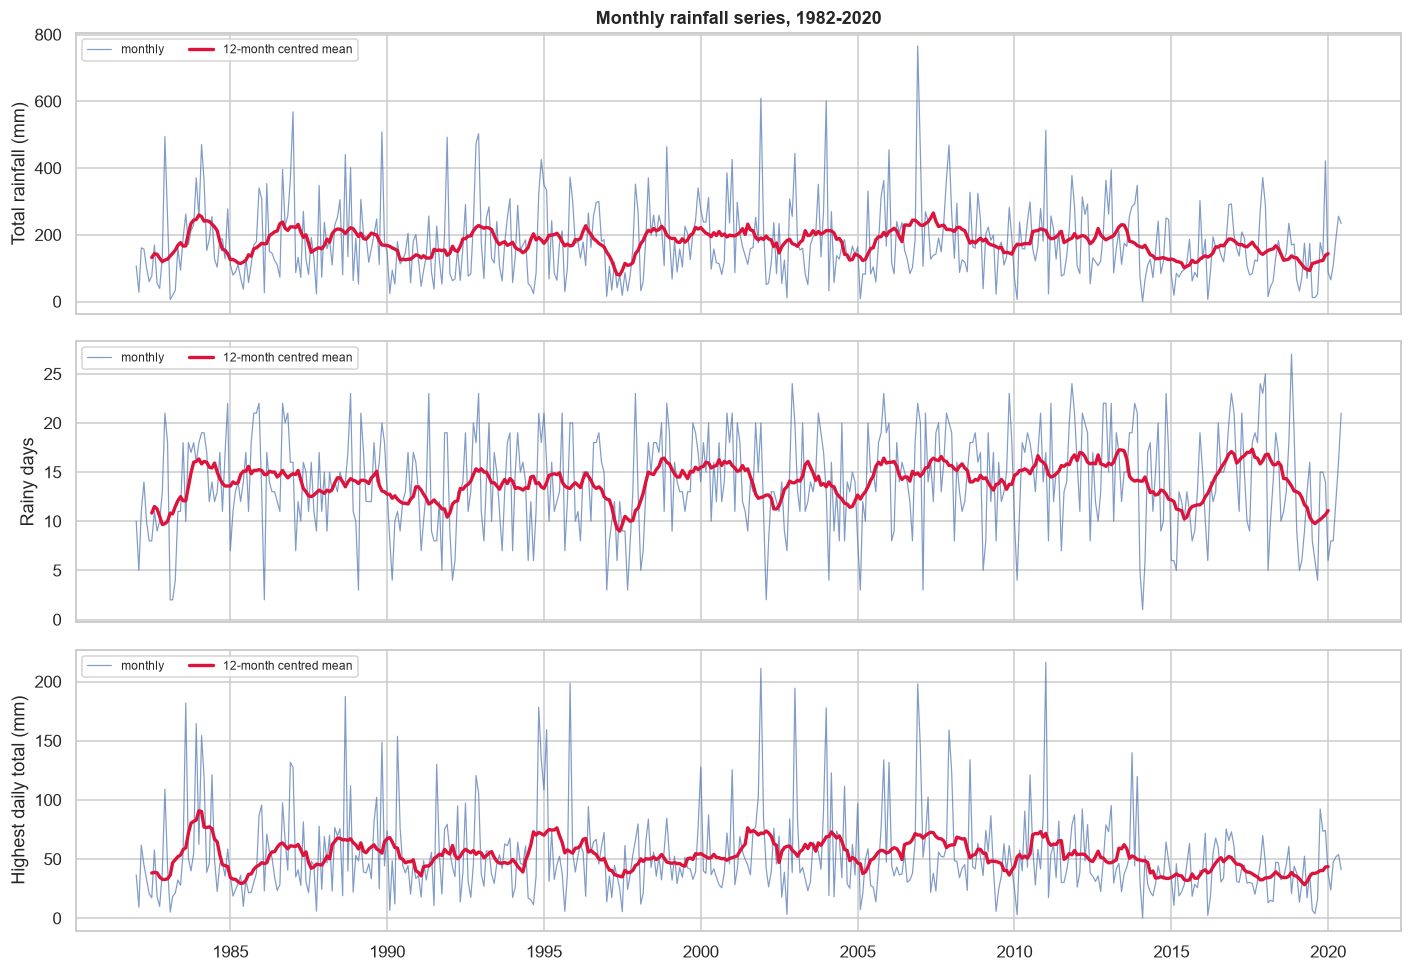

In [55]:
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, (c, lab) in zip(axes, [("total_mm", "Total rainfall (mm)"), ("rain_days", "Rainy days"), ("max_daily_mm", "Highest daily total (mm)")]):
    ax.plot(df.index, df[c], lw=0.8, alpha=0.7, label="monthly")
    ax.plot(df.index, df[c].rolling(12, center=True).mean(), lw=2.2, color="crimson", label="12-month centred mean")
    ax.set_ylabel(lab); ax.legend(loc="upper left", ncol=2, fontsize=8)
axes[0].set_title("Monthly rainfall series, 1982-2020")
plt.tight_layout(); plt.show()

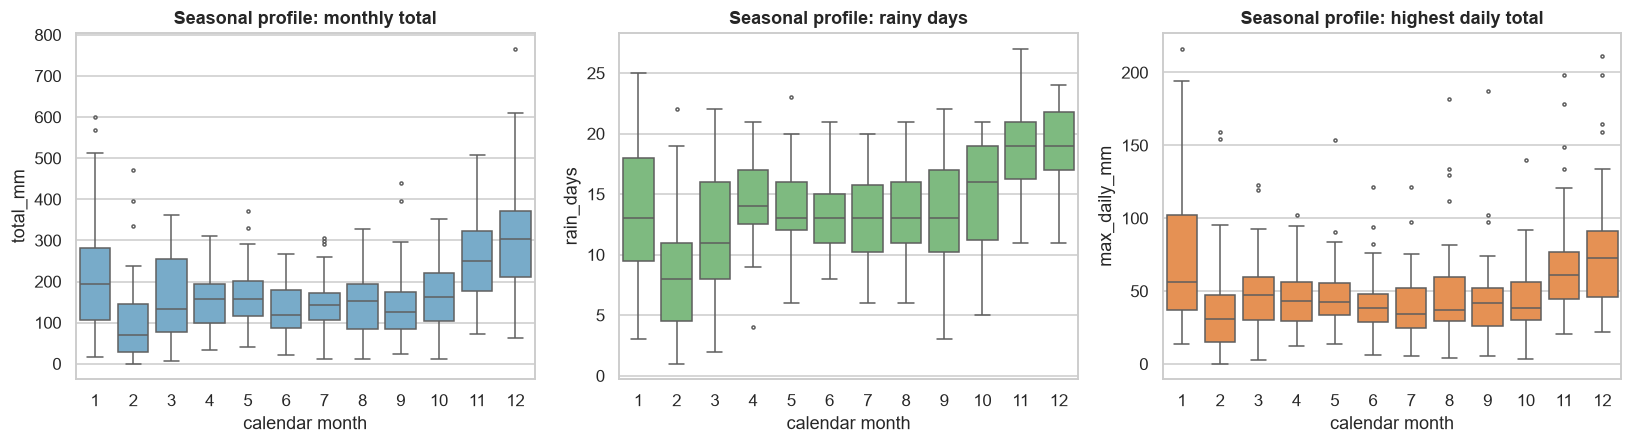

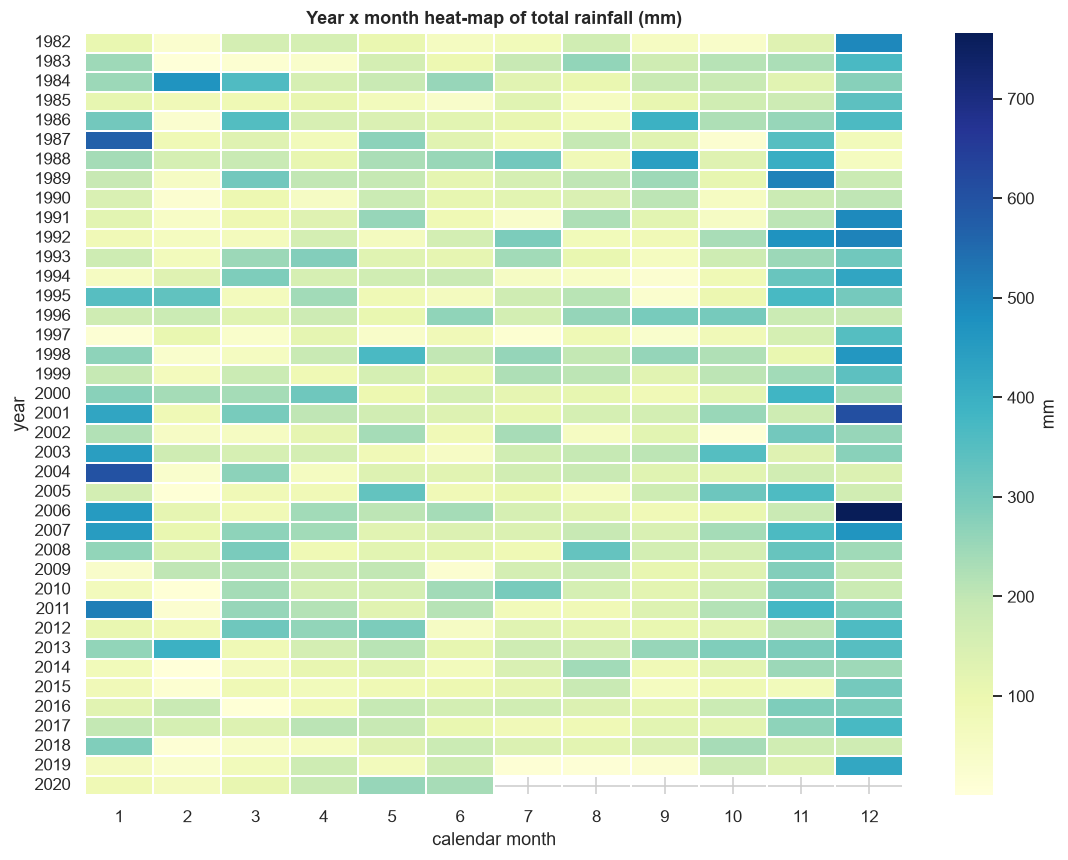

In [56]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sns.boxplot(data=df, x="month_num", y="total_mm", ax=axes[0], color="#6baed6", fliersize=2)
axes[0].set_title("Seasonal profile: monthly total"); axes[0].set_xlabel("calendar month")
sns.boxplot(data=df, x="month_num", y="rain_days", ax=axes[1], color="#74c476", fliersize=2)
axes[1].set_title("Seasonal profile: rainy days"); axes[1].set_xlabel("calendar month")
sns.boxplot(data=df, x="month_num", y="max_daily_mm", ax=axes[2], color="#fd8d3c", fliersize=2)
axes[2].set_title("Seasonal profile: highest daily total"); axes[2].set_xlabel("calendar month")
plt.tight_layout(); plt.show()

heat = df.pivot_table(index="year", columns="month_num", values="total_mm")
plt.figure(figsize=(12, 9)); sns.heatmap(heat, cmap="YlGnBu", cbar_kws={"label": "mm"}, linewidths=0.2)
plt.title("Year x month heat-map of total rainfall (mm)"); plt.xlabel("calendar month"); plt.show()

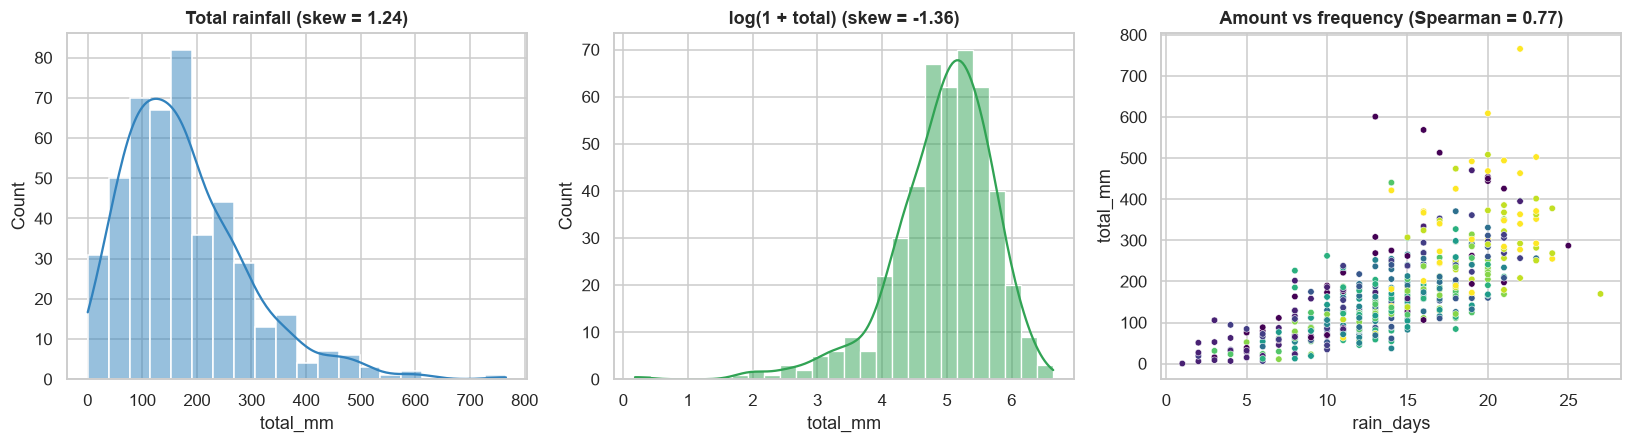

Share of Var[log total] attributable to rain-day frequency: 43% | to intensity: 57%  (sums to 100%)
=> Both matter; neither is negligible, so forecasting 'total' alone hides two distinct mechanisms.


In [57]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sns.histplot(df.total_mm, kde=True, ax=axes[0], color="#3182bd"); axes[0].set_title(f"Total rainfall (skew = {df.total_mm.skew():.2f})")
sns.histplot(np.log1p(df.total_mm), kde=True, ax=axes[1], color="#31a354"); axes[1].set_title(f"log(1 + total) (skew = {np.log1p(df.total_mm).skew():.2f})")
sns.scatterplot(data=df, x="rain_days", y="total_mm", hue="month_num", palette="viridis", ax=axes[2], s=18, legend=False)
axes[2].set_title(f"Amount vs frequency (Spearman = {stats.spearmanr(df.rain_days, df.total_mm)[0]:.2f})")
plt.tight_layout(); plt.show()

# H3: variance decomposition of log(total) = log(days) + log(intensity)
lt, ld, li = np.log(df.total_mm), np.log(df.rain_days), np.log(df.intensity)
cov_d, cov_i = np.cov(lt, ld)[0, 1] / lt.var(), np.cov(lt, li)[0, 1] / lt.var()
print(f"Share of Var[log total] attributable to rain-day frequency: {cov_d:.0%} | to intensity: {cov_i:.0%}  (sums to 100%)")
print("=> Both matter; neither is negligible, so forecasting 'total' alone hides two distinct mechanisms.")

In [58]:
clim = df.groupby("month_num").agg(mean_mm=("total_mm", "mean"), sd_mm=("total_mm", "std"),
                                   mean_days=("rain_days", "mean"), mean_intensity=("intensity", "mean"),
                                   median_max_daily=("max_daily_mm", "median"))
clim["cv"] = clim.sd_mm / clim.mean_mm
clim.index.name = "month"
display(clim.round(1))
print("Wettest month on average:", clim.mean_mm.idxmax(), "| driest:", clim.mean_mm.idxmin(),
      f"| wet/dry ratio = {clim.mean_mm.max()/clim.mean_mm.min():.1f}x")

,mean_mm,sd_mm,mean_days,mean_intensity,median_max_daily,cv
month,,,,,,
1,226.0,152.8,13.4,16.1,56.2,0.7
2,104.7,107.0,8.3,11.5,31.0,1.0
3,160.3,103.2,12.2,12.5,47.4,0.6
4,153.0,67.7,14.4,10.6,42.9,0.4
5,165.8,75.3,14.0,11.7,42.8,0.5
6,134.3,65.7,12.9,10.2,38.4,0.5
7,146.3,72.5,13.3,10.9,34.4,0.5
8,147.1,70.5,13.7,11.0,37.2,0.5
9,145.7,93.2,13.1,10.6,41.8,0.6


Wettest month on average: 12 | driest: 2 | wet/dry ratio = 3.0x


## 3. Statistical inference: trend, change-point, stationarity, seasonality
Eyeballing a rolling mean is not evidence. I use distribution-free tests appropriate for skewed, autocorrelated climate series.
- **Mann–Kendall** (monotonic trend) + **Theil–Sen** slope (robust magnitude, with CI) on *annual* aggregates (removes seasonality).
- **Pettitt** test for a single abrupt change-point.
- **ADF + KPSS** jointly for stationarity (they have opposite nulls — agreement is informative).
- **STL** decomposition and a quantitative **seasonal-strength** index.

In [59]:
def mann_kendall(x):
    x = np.asarray(x, float); n = len(x)
    s = sum(np.sign(x[j] - x[i]) for i in range(n - 1) for j in range(i + 1, n))
    _, c = np.unique(x, return_counts=True)
    var = (n * (n - 1) * (2 * n + 5) - np.sum(c * (c - 1) * (2 * c + 5))) / 18
    z = 0.0 if s == 0 else (s - np.sign(s)) / np.sqrt(var)
    return s, z, 2 * (1 - stats.norm.cdf(abs(z)))

def pettitt(x):
    x = np.asarray(x, float); n = len(x); r = stats.rankdata(x)
    U = np.array([2 * r[:t].sum() - t * (n + 1) for t in range(1, n)])
    k = np.argmax(np.abs(U)); K = abs(U[k])
    return k + 1, min(1.0, 2 * np.exp(-6 * K**2 / (n**3 + n**2)))

rows = []
for c in ["total_mm", "rain_days", "max_daily_mm", "intensity"]:
    y = annual[c].values; x = annual.index.values
    s, z, p = mann_kendall(y)
    slope, _, lo, hi = stats.theilslopes(y, x)
    cp, pp = pettitt(y)
    rows.append(dict(metric=c, MK_z=z, MK_p=p, sen_slope_per_year=slope, slope_CI_lo=lo, slope_CI_hi=hi,
                     pettitt_change_year=int(annual.index[cp - 1]), pettitt_p=pp,
                     lag1_autocorr=pd.Series(y).autocorr(1)))
trend_tbl = pd.DataFrame(rows).set_index("metric")
display(trend_tbl.round(3))
print("p < 0.05 => evidence of trend / shift. Low lag-1 autocorrelation means MK p-values are not much inflated by serial dependence.")
print(f"Multiplicity: 4 metrics were tested, so a Bonferroni-adjusted threshold is 0.05/4 = {0.05/4:.4f}. Treat results between that and 0.05 as suggestive, not conclusive.")

,MK_z,MK_p,sen_slope_per_year,slope_CI_lo,slope_CI_hi,pettitt_change_year,pettitt_p,lag1_autocorr
metric,,,,,,,,
total_mm,-0.70,0.48,-5.39,-20.17,10.98,2013,0.28,-0.06
rain_days,2.00,0.04,0.60,0.00,1.29,1997,0.14,0.08
max_daily_mm,-1.89,0.06,-1.34,-2.88,0.03,2011,0.09,0.22
intensity,-2.44,0.01,-0.08,-0.12,-0.02,2007,0.04,0.04


p < 0.05 => evidence of trend / shift. Low lag-1 autocorrelation means MK p-values are not much inflated by serial dependence.
Multiplicity: 4 metrics were tested, so a Bonferroni-adjusted threshold is 0.05/4 = 0.0125. Treat results between that and 0.05 as suggestive, not conclusive.


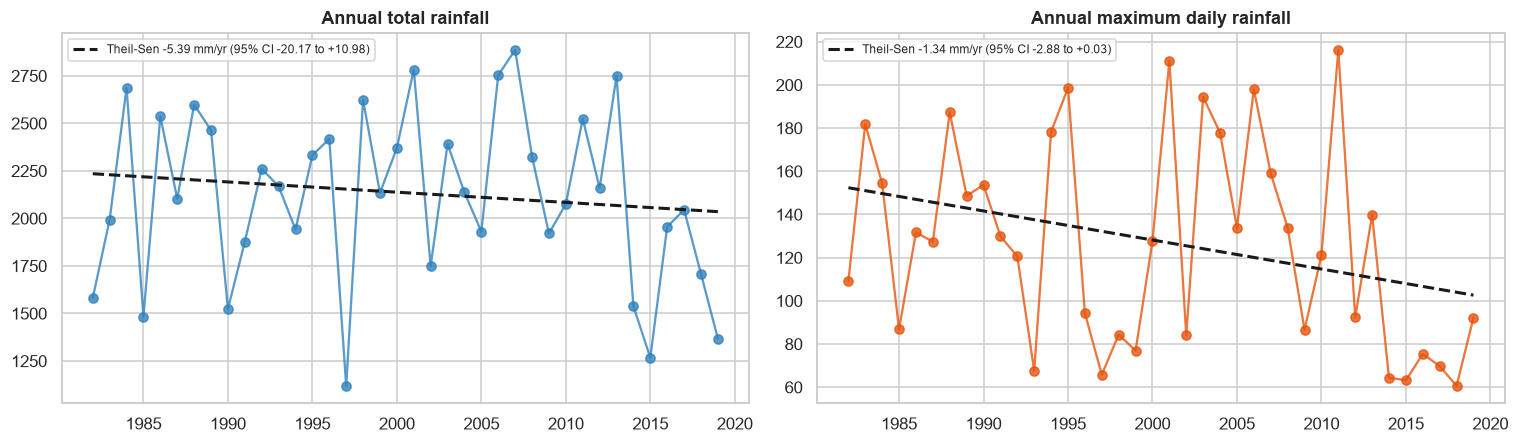

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, c, col in zip(axes, ["total_mm", "max_daily_mm"], ["#3182bd", "#e6550d"]):
    y = annual[c]; slope, icpt, lo, hi = stats.theilslopes(y.values, y.index.values)
    ax.plot(y.index, y, "o-", color=col, alpha=0.8); ax.plot(y.index, icpt + slope * y.index, "k--", lw=2,
            label=f"Theil-Sen {slope:+.2f} mm/yr (95% CI {lo:+.2f} to {hi:+.2f})")
    ax.set_title(f"Annual {'total' if c=='total_mm' else 'maximum daily'} rainfall"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

ADF  (H0: unit root)        p = 0.0000
KPSS (H0: stationary)       p = 0.1000  (statsmodels clips p to [0.01, 0.10])
Joint verdict: stationary around a (seasonal) mean => seasonal *regression* (not unit-root differencing) is the right structural choice.
Seasonal strength Fs = 0.35 | Trend strength Ft = 0.14   (0 = none, 1 = deterministic)


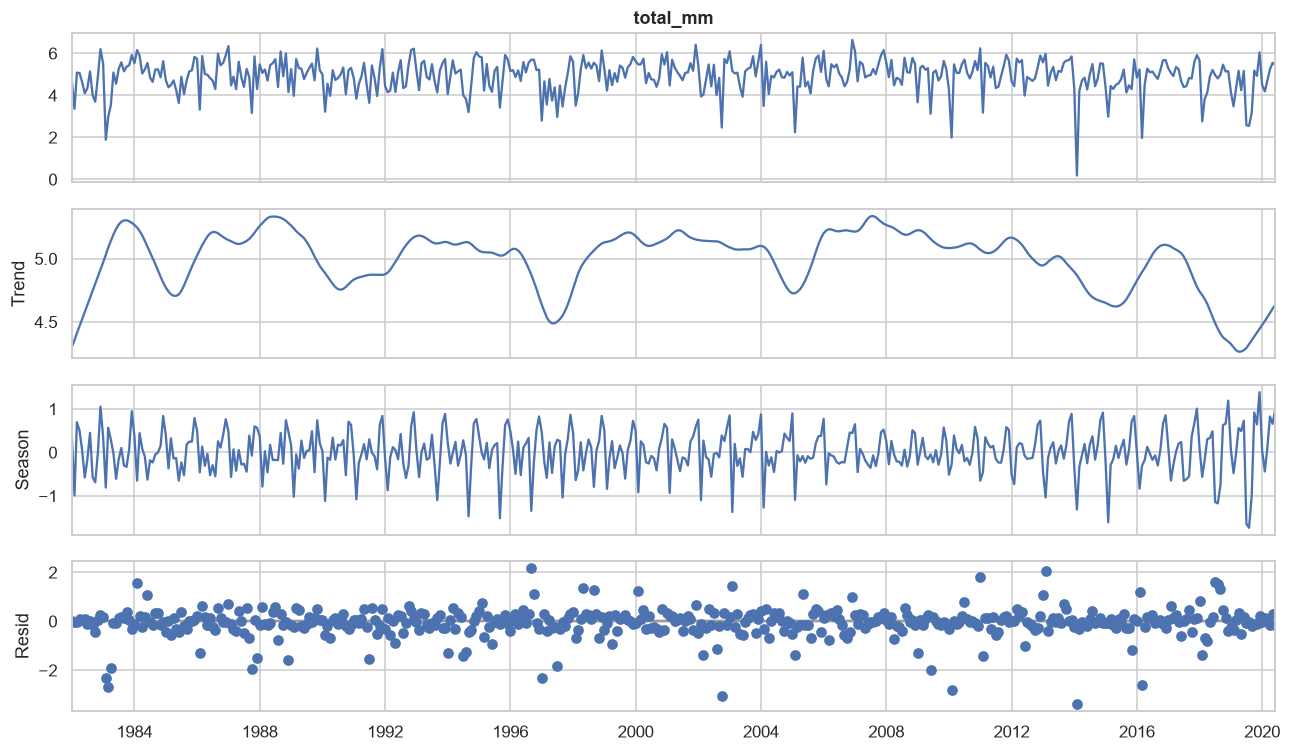

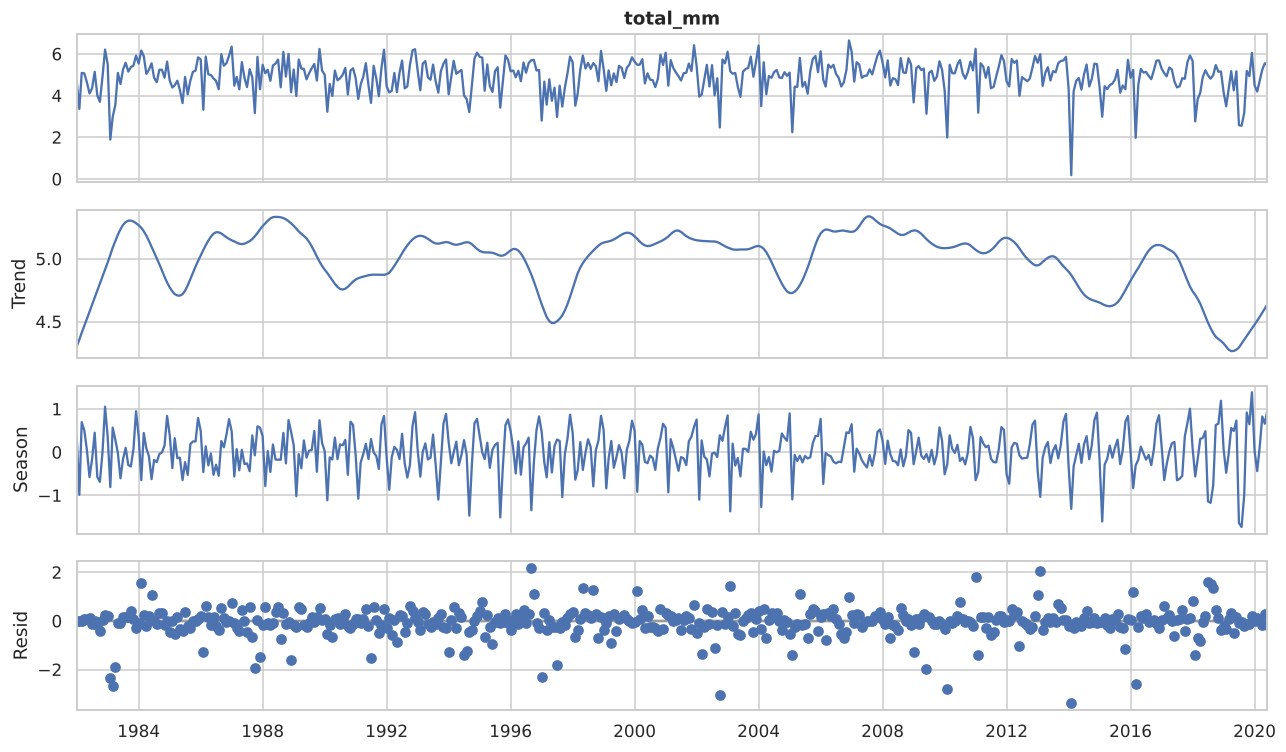

In [61]:
y = df.total_mm
ylog = np.log1p(y)
adf_p  = adfuller(ylog, autolag="AIC")[1]
kpss_p = kpss(ylog, regression="c", nlags="auto")[1]
print(f"ADF  (H0: unit root)        p = {adf_p:.4f}")
print(f"KPSS (H0: stationary)       p = {kpss_p:.4f}  (statsmodels clips p to [0.01, 0.10])")
verdict = ("stationary around a (seasonal) mean" if adf_p < .05 and kpss_p > .05 else "ambiguous - inspect")
print("Joint verdict:", verdict, "=> seasonal *regression* (not unit-root differencing) is the right structural choice.")

stl = STL(ylog, period=12, robust=True).fit()
Ft = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
Fs = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
print(f"Seasonal strength Fs = {Fs:.2f} | Trend strength Ft = {Ft:.2f}   (0 = none, 1 = deterministic)")
fig = stl.plot(); fig.set_size_inches(12, 7); plt.tight_layout(); plt.show()

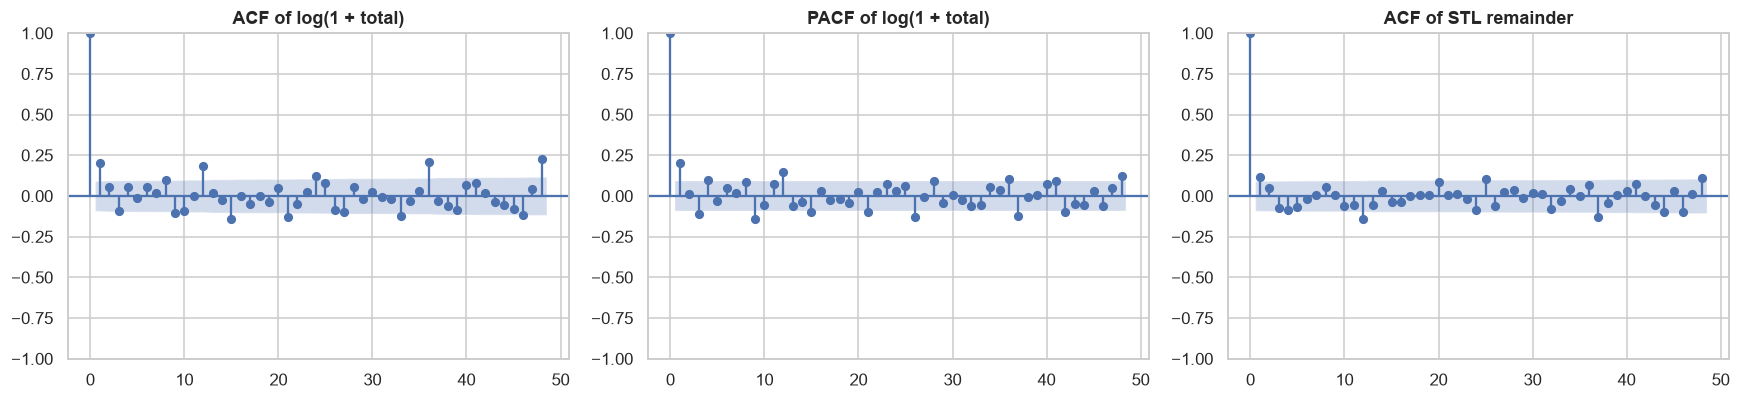

Ljung-Box on STL remainder:


,lb_stat,lb_pvalue
12,30.49,2.35e-03
24,41.35,1.53e-02


Takeaway: the remainder is NOT white noise (Ljung-Box rejects), so some short-memory structure survives deseasonalising - that is why the ARMA error term in the DHR model is justified. Seasonal strength is moderate, so expect modest predictability overall.


In [62]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
plot_acf(ylog, lags=48, ax=axes[0]); axes[0].set_title("ACF of log(1 + total)")
plot_pacf(ylog, lags=48, ax=axes[1], method="ywm"); axes[1].set_title("PACF of log(1 + total)")
plot_acf(stl.resid, lags=48, ax=axes[2]); axes[2].set_title("ACF of STL remainder")
plt.tight_layout(); plt.show()
lb = acorr_ljungbox(stl.resid, lags=[12, 24], return_df=True)
print("Ljung-Box on STL remainder:"); display(lb)
print("Takeaway: the remainder is NOT white noise (Ljung-Box rejects), so some short-memory structure survives deseasonalising - that is why the ARMA error term in the DHR model is justified. Seasonal strength is moderate, so expect modest predictability overall.")

## 4. Extreme-value analysis: how bad can a single day get?
Block-maxima theory says annual maxima follow a **Generalised Extreme Value (GEV)** law. I fit GEV to the 38 annual maxima of daily rainfall, check the fit with a QQ plot, and report **return levels** with **parametric-bootstrap confidence intervals**.

> Convention note: `scipy.stats.genextreme` uses shape `c = -ξ`. I report ξ (the conventional tail index): ξ > 0 heavy tail, ξ = 0 Gumbel, ξ < 0 bounded tail.

GEV fit: xi = -0.137, location = 106.6 mm, scale = 41.6 mm  (n = 38 annual maxima)
KS goodness-of-fit p = 0.485
Bootstrap: kept 995/1000 non-degenerate refits


,level_mm,CI95_lo,CI95_hi
return_period_yrs,,,
2,121.4,106.4,137.1
5,163.0,142.2,180.1
10,187.2,160.0,207.5
25,214.4,177.5,246.0
50,232.4,185.9,281.6
100,248.6,193.3,314.6


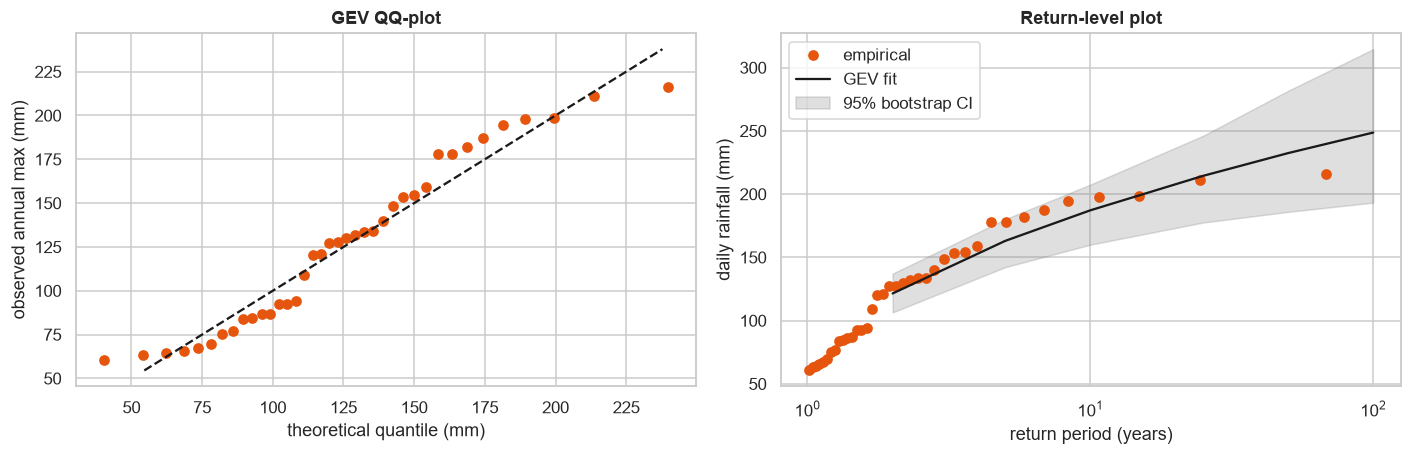

Largest daily total on record: 216.2 mm in Jan 2011
Caution: 38 years cannot pin down a 100-year event - note how the CI widens with T. Use the 100-yr value as an order of magnitude, not a design number.


Largest daily total on record: 216.2 mm in Jan 2011
Caution: 38 years cannot pin down a 100-year event - note how the CI widens with T. Use the 100-yr value as an order of magnitude, not a design number.


In [63]:
am = annual.max_daily_mm.values
c, loc, scale = stats.genextreme.fit(am)
xi = -c
print(f"GEV fit: xi = {xi:.3f}, location = {loc:.1f} mm, scale = {scale:.1f} mm  (n = {len(am)} annual maxima)")
ks = stats.kstest(am, "genextreme", args=(c, loc, scale)); print(f"KS goodness-of-fit p = {ks.pvalue:.3f}")

T = np.array([2, 5, 10, 25, 50, 100])
def return_levels(c_, loc_, scale_): return stats.genextreme.ppf(1 - 1 / T, c_, loc_, scale_)
rl = return_levels(c, loc, scale)

B = 1000; boot = []
for b in range(B):
    sample = stats.genextreme.rvs(c, loc, scale, size=len(am), random_state=int(rng.integers(1e9)))
    try:
        cb, lb, sb = stats.genextreme.fit(sample, c, loc=loc, scale=scale)   # warm-start from the MLE for stability
    except Exception:
        continue
    if abs(cb) <= 0.5:                                                        # drop degenerate refits (|xi| > 0.5)
        boot.append(return_levels(cb, lb, sb))
boot = np.array(boot); print(f"Bootstrap: kept {len(boot)}/{B} non-degenerate refits")
lo, hi = np.nanpercentile(boot, [2.5, 97.5], axis=0)
rl_tbl = pd.DataFrame({"return_period_yrs": T, "level_mm": rl, "CI95_lo": lo, "CI95_hi": hi}).set_index("return_period_yrs")
display(rl_tbl.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
srt = np.sort(am); pp = (np.arange(1, len(srt) + 1) - 0.44) / (len(srt) + 0.12)
axes[0].scatter(stats.genextreme.ppf(pp, c, loc, scale), srt, color="#e6550d")
lim = [srt.min() * 0.9, srt.max() * 1.1]; axes[0].plot(lim, lim, "k--"); axes[0].set_title("GEV QQ-plot")
axes[0].set_xlabel("theoretical quantile (mm)"); axes[0].set_ylabel("observed annual max (mm)")
emp_T = 1 / (1 - pp)
axes[1].semilogx(emp_T, srt, "o", color="#e6550d", label="empirical"); axes[1].semilogx(T, rl, "k-", label="GEV fit")
axes[1].fill_between(T, lo, hi, alpha=0.25, color="grey", label="95% bootstrap CI")
axes[1].set_title("Return-level plot"); axes[1].set_xlabel("return period (years)"); axes[1].set_ylabel("daily rainfall (mm)"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"Largest daily total on record: {df.max_daily_mm.max():.1f} mm in {df.max_daily_mm.idxmax():%b %Y}")
print("Caution: 38 years cannot pin down a 100-year event - note how the CI widens with T. Use the 100-yr value as an order of magnitude, not a design number.")

## 5. Leak-free feature engineering for forecasting
**Rule:** to forecast any month within a 12-month horizon, a feature may only use information that exists *at the forecast origin*. Therefore every lag-based feature uses **lag ≥ 12**. This single design choice removes recursive-forecast error compounding *and* makes the backtest honest.

Features: calendar harmonics (sin/cos, 2 harmonics), lag-12/24/36 totals, trailing 24-month mean ending at lag 12 (wetness regime), prior same-calendar-month climatology (expanding mean), and lag-12 rainy days / peak.

In [64]:
def make_features(frame):
    X = pd.DataFrame(index=frame.index); m = frame.index.month
    for k in (1, 2):
        X[f"sin{k}"] = np.sin(2 * np.pi * k * m / 12); X[f"cos{k}"] = np.cos(2 * np.pi * k * m / 12)
    for L in (12, 24, 36):
        X[f"total_lag{L}"] = frame.total_mm.shift(L)
    X["total_roll24_lag12"] = frame.total_mm.shift(12).rolling(24).mean()
    X["days_lag12"] = frame.rain_days.shift(12)
    X["max_lag12"]  = frame.max_daily_mm.shift(12)
    X["same_month_clim"] = frame.groupby(frame.index.month).total_mm.transform(lambda s: s.shift(1).expanding().mean())
    return X

# Extend the index 12 months ahead so the SAME feature code produces production-time features.
ext_index = pd.date_range(df.index.min(), df.index.max() + pd.DateOffset(months=12), freq="MS")
dfx = df[["total_mm", "rain_days", "max_daily_mm"]].reindex(ext_index)
FEATS = make_features(dfx)
print("Feature matrix:", FEATS.shape, "| future rows have features but no target:", int(dfx.total_mm.isna().sum()))

# Leakage unit-test: features at month t must not change if all data from t-11 onward is destroyed.
t = pd.Timestamp("2010-03-01")
corrupt = dfx.copy(); corrupt.loc[t - pd.DateOffset(months=11):, :] = np.nan
assert np.allclose(make_features(corrupt).loc[t].fillna(-1), FEATS.loc[t].fillna(-1)), "Leakage detected!"
print("✓ Leakage test passed: features at t depend only on data up to t-12.")

Feature matrix: (474, 11) | future rows have features but no target: 12
✓ Leakage test passed: features at t depend only on data up to t-12.


## 6. Modelling: baselines → statistical → ML → ensemble
| Model | Why it is here |
|---|---|
| **Seasonal-naive** | Same month last year. The minimum bar. |
| **Climatology** | Mean of that calendar month in training. Strong for a stable seasonal cycle. |
| **ETS (Holt-Winters)** | Classical exponential smoothing with additive seasonality on log scale. |
| **DHR-ARIMA** | Dynamic harmonic regression: Fourier seasonality + ARMA errors, order chosen by AIC on the *earliest* training window only. |
| **Gradient boosting (gamma loss)** | Non-linear use of lag/regime features; gamma loss respects positive, skewed targets. |
| **Ensemble** | Equal-weight mean of ETS, DHR-ARIMA and GBM (forecast combination is a robust, hard-to-beat default). |

**Validation design.** Rolling-origin (expanding-window) backtest with 12-month horizon:
- **CV folds:** 8 origins, Jul-2009 → Jul-2016 (used for model comparison and interval calibration).
- **Final holdout:** 3 origins, Jul-2017 → Jul-2019 (36 months, *never used for any decision*).

In [65]:
CV_ORIGINS      = pd.date_range("2009-07-01", "2016-07-01", freq="12MS")
HOLDOUT_ORIGINS = pd.date_range("2017-07-01", "2019-07-01", freq="12MS")
H = 12
y_all = dfx.total_mm

def fourier(index, K):
    m = index.month.values; cols = {}
    for k in range(1, K + 1):
        cols[f"s{k}"] = np.sin(2 * np.pi * k * m / 12); cols[f"c{k}"] = np.cos(2 * np.pi * k * m / 12)
    return pd.DataFrame(cols, index=index)

# ---- model order selection (earliest window ONLY -> no peeking at CV/holdout) ----
sel_train = y_all[: CV_ORIGINS[0] - pd.DateOffset(months=1)]
grid = []
for K in (2, 3):
    for p in (0, 1, 2):
        for q in (0, 1):
            try:
                r = SARIMAX(np.log1p(sel_train), exog=fourier(sel_train.index, K), order=(p, 0, q), trend="c").fit(disp=False)
                grid.append(dict(K=K, p=p, q=q, aic=r.aic))
            except Exception: pass
grid = pd.DataFrame(grid).sort_values("aic").reset_index(drop=True)
BEST = grid.iloc[0]; display(grid.head(5).round(1))
print(f"Selected DHR-ARIMA: K={int(BEST.K)} harmonics, ARMA({int(BEST.p)},{int(BEST.q)})")

,K,p,q,aic
0,3,2,1,674.4
1,3,2,0,681.0
2,3,1,1,685.6
3,3,1,0,690.1
4,3,0,1,691.3


Selected DHR-ARIMA: K=3 harmonics, ARMA(2,1)


In [66]:
def fc_snaive(origin, idx):
    return np.array([y_all.loc[d - pd.DateOffset(years=1)] for d in idx])

def fc_climatology(origin, idx):
    tr = y_all[:origin - pd.DateOffset(months=1)]
    mu = tr.groupby(tr.index.month).mean()
    return mu.reindex(idx.month).values

def fc_ets(origin, idx):
    tr = np.log1p(y_all[:origin - pd.DateOffset(months=1)])
    fit = ExponentialSmoothing(tr, trend=None, seasonal="add", seasonal_periods=12).fit()
    f = fit.forecast(len(idx)).values
    return np.exp(f) * np.mean(np.exp(fit.resid)) - 1     # Duan smearing: distribution-free back-transform bias correction

def fc_dhr(origin, idx):
    tr = y_all[:origin - pd.DateOffset(months=1)]; K, p, q = int(BEST.K), int(BEST.p), int(BEST.q)
    fit = SARIMAX(np.log1p(tr), exog=fourier(tr.index, K), order=(p, 0, q), trend="c").fit(disp=False)
    f = fit.forecast(len(idx), exog=fourier(idx, K)).values
    return np.exp(f) * np.mean(np.exp(fit.resid[12:])) - 1   # Duan smearing

GBM_PARAMS = dict(loss="gamma", learning_rate=0.04, max_iter=250, max_depth=3, min_samples_leaf=20,
                  l2_regularization=1.0, random_state=SEED)
def fc_gbm(origin, idx):
    tr_idx = y_all[:origin - pd.DateOffset(months=1)].dropna().index
    mdl = HistGradientBoostingRegressor(**GBM_PARAMS).fit(FEATS.loc[tr_idx], y_all.loc[tr_idx].clip(lower=0.1))
    return mdl.predict(FEATS.loc[idx])

BASE_MODELS = {"Seasonal-naive": fc_snaive, "Climatology": fc_climatology, "ETS": fc_ets,
               "DHR-ARIMA": fc_dhr, "GBM": fc_gbm}

def backtest(origins, split):
    out = []
    for o in origins:
        idx = pd.date_range(o, periods=H, freq="MS"); preds = {n: f(o, idx) for n, f in BASE_MODELS.items()}
        preds["Ensemble"] = np.mean([preds["ETS"], preds["DHR-ARIMA"], preds["GBM"]], axis=0)
        for n, p in preds.items():
            out.append(pd.DataFrame({"date": idx, "origin": o, "horizon": np.arange(1, H + 1), "model": n,
                                     "y": y_all.loc[idx].values, "pred": p, "split": split}))
    return pd.concat(out, ignore_index=True)

bt = pd.concat([backtest(CV_ORIGINS, "cv"), backtest(HOLDOUT_ORIGINS, "holdout")], ignore_index=True)
print("Backtest rows:", len(bt), "| models:", bt.model.nunique(), "| folds:", bt.origin.nunique())

Backtest rows: 792 | models: 6 | folds: 11


In [67]:
# MASE scale: in-sample seasonal-naive MAE on data available before the CV period (no leakage)
train0 = y_all[: CV_ORIGINS[0] - pd.DateOffset(months=1)]
MASE_SCALE = np.mean(np.abs(train0.values[12:] - train0.values[:-12]))

def metrics(g):
    e = g.pred - g.y
    return pd.Series({"MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e**2)),
                      "MASE": np.mean(np.abs(e)) / MASE_SCALE, "Bias": e.mean(),
                      "RMSLE": np.sqrt(np.mean((np.log1p(g.pred.clip(lower=0)) - np.log1p(g.y))**2))})

res = bt.groupby(["split", "model"]).apply(metrics).round(2)
clim_mae = res.xs("Climatology", level="model")["MAE"]
res["Skill_vs_clim_%"] = [100 * (1 - r.MAE / clim_mae[s]) for (s, _), r in res.iterrows()]
order = ["Seasonal-naive", "Climatology", "ETS", "DHR-ARIMA", "GBM", "Ensemble"]
for s in ("cv", "holdout"):
    print(f"\n=== {s.upper()} ({'model selection' if s=='cv' else 'untouched'}) ===")
    display(res.loc[s].loc[order].round(2).style.highlight_min(subset=["MAE", "RMSE", "MASE", "RMSLE"], color="#c7e9c0"))


=== CV (model selection) ===


,MAE,RMSE,MASE,Bias,RMSLE,Skill_vs_clim_%
model,,,,,,
Seasonal-naive,86.850000,122.350000,0.770000,-0.110000,1.100000,-29.700000
Climatology,66.960000,87.020000,0.590000,11.870000,0.830000,0.000000
ETS,66.860000,88.440000,0.590000,16.190000,0.810000,0.150000
DHR-ARIMA,68.880000,89.050000,0.610000,17.320000,0.820000,-2.870000
GBM,65.760000,87.270000,0.580000,2.680000,0.810000,1.790000
Ensemble,65.320000,86.170000,0.580000,12.060000,0.810000,2.450000



=== HOLDOUT (untouched) ===


,MAE,RMSE,MASE,Bias,RMSLE,Skill_vs_clim_%
model,,,,,,
Seasonal-naive,82.160000,102.340000,0.730000,12.920000,0.960000,-9.930000
Climatology,74.740000,86.890000,0.660000,37.840000,0.920000,0.000000
ETS,73.600000,88.200000,0.650000,43.350000,0.900000,1.530000
DHR-ARIMA,71.980000,87.200000,0.640000,45.180000,0.910000,3.690000
GBM,76.140000,89.480000,0.680000,40.770000,0.920000,-1.870000
Ensemble,73.420000,86.580000,0.650000,43.100000,0.910000,1.770000


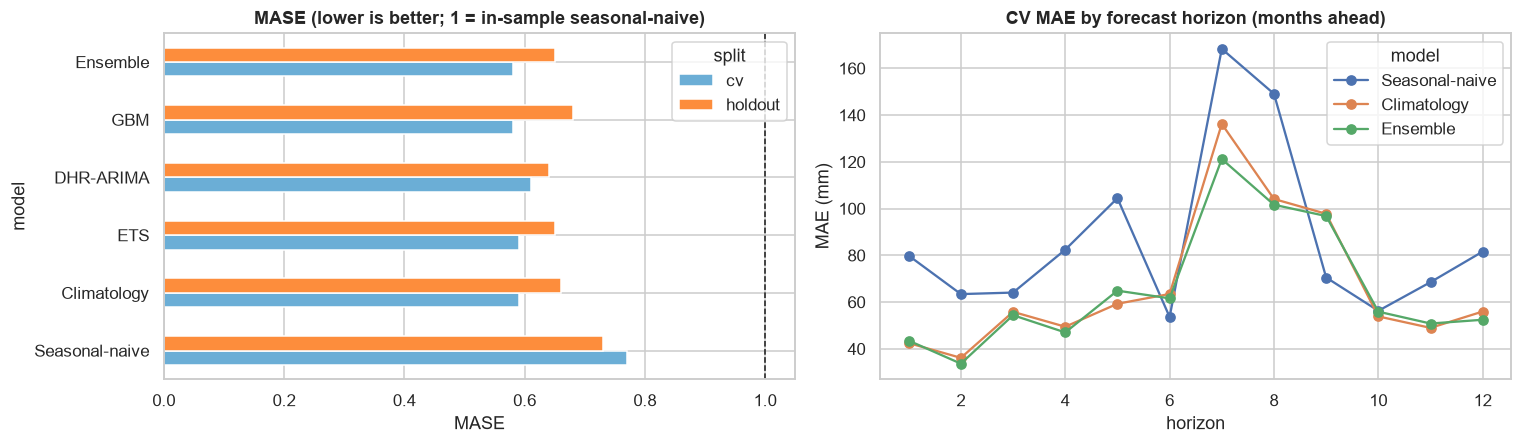

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
piv = res.reset_index().pivot(index="model", columns="split", values="MASE").loc[order]
piv.plot.barh(ax=axes[0], color=["#6baed6", "#fd8d3c"]); axes[0].axvline(1, color="k", ls="--", lw=1)
axes[0].set_title("MASE (lower is better; 1 = in-sample seasonal-naive)"); axes[0].set_xlabel("MASE")

h_err = bt[bt.split == "cv"].assign(ae=lambda d: (d.pred - d.y).abs()).groupby(["horizon", "model"]).ae.mean().unstack()[order]
h_err[["Seasonal-naive", "Climatology", "Ensemble"]].plot(ax=axes[1], marker="o")
axes[1].set_title("CV MAE by forecast horizon (months ahead)"); axes[1].set_ylabel("MAE (mm)")
plt.tight_layout(); plt.show()

### Is the improvement real? Paired significance test
Point metrics on ~100 forecasts are noisy. I test the *paired* absolute-error differences with a Wilcoxon signed-rank test (non-parametric, appropriate for skewed errors), pooling CV + holdout for power.

In [69]:
ae = (bt.assign(ae=(bt.pred - bt.y).abs()).pivot_table(index=["origin", "date"], columns="model", values="ae"))
rows = []
for a, b in [("Ensemble", "Seasonal-naive"), ("Ensemble", "Climatology"), ("GBM", "Climatology"), ("DHR-ARIMA", "Climatology"), ("Ensemble", "DHR-ARIMA")]:
    d = ae[b] - ae[a]                      # positive => 'a' better
    w = stats.wilcoxon(d, alternative="two-sided")
    rows.append(dict(comparison=f"{a} vs {b}", mean_MAE_gain_mm=d.mean(), median_gain_mm=d.median(), wilcoxon_p=w.pvalue, n=len(d)))
sig = pd.DataFrame(rows).set_index("comparison")
display(sig.round(3))
print("Positive gain = first model has lower error. Treat p-values as indicative: forecast errors within a fold are correlated.")

,mean_MAE_gain_mm,median_gain_mm,wilcoxon_p,n
comparison,,,,
Ensemble vs Seasonal-naive,18.04,13.39,0.01,132
Ensemble vs Climatology,1.55,2.52,0.29,132
GBM vs Climatology,0.49,1.33,0.75,132
DHR-ARIMA vs Climatology,-0.64,0.48,0.83,132
Ensemble vs DHR-ARIMA,2.19,1.91,0.09,132


Positive gain = first model has lower error. Treat p-values as indicative: forecast errors within a fold are correlated.


## 7. Prediction intervals & calibration
A point forecast without uncertainty is not decision-grade. I build **split-conformal intervals** for the ensemble from *CV residuals only* (log scale → approximately homoscedastic, always positive after back-transform), then check **empirical coverage on the untouched holdout**.

Nominal coverage 90% | CV (in-sample for calibration) 90% | HOLDOUT (out-of-sample) 89%  (n=36)
Mean interval width: 281 mm  vs. mean actual 141 mm


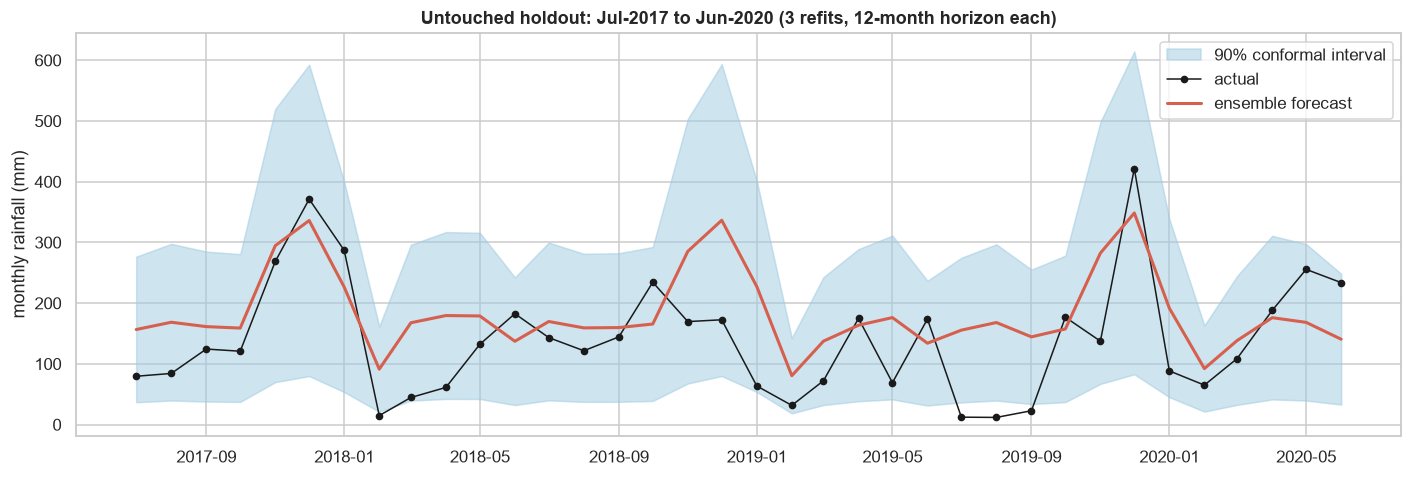

In [70]:
ens = bt[bt.model == "Ensemble"].copy()
ens["r"] = np.log1p(ens.y) - np.log1p(ens.pred.clip(lower=0))
cv_r = ens[ens.split == "cv"].r.values
ALPHA = 0.10
q_lo, q_hi = np.quantile(cv_r, [ALPHA / 2, 1 - ALPHA / 2])
def interval(pred): 
    return np.expm1(np.log1p(pred) + q_lo), np.expm1(np.log1p(pred) + q_hi)

ho = ens[ens.split == "holdout"].copy().sort_values("date")
ho["lo"], ho["hi"] = interval(ho.pred)
cov = ((ho.y >= ho.lo) & (ho.y <= ho.hi)).mean()
cv_ = ens[ens.split == "cv"].copy(); cv_["lo"], cv_["hi"] = interval(cv_.pred)
print(f"Nominal coverage {1-ALPHA:.0%} | CV (in-sample for calibration) {((cv_.y>=cv_.lo)&(cv_.y<=cv_.hi)).mean():.0%} | HOLDOUT (out-of-sample) {cov:.0%}  (n={len(ho)})")
print(f"Mean interval width: {np.mean(ho.hi - ho.lo):.0f} mm  vs. mean actual {ho.y.mean():.0f} mm")

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.fill_between(ho.date, ho.lo, ho.hi, color="#9ecae1", alpha=0.5, label="90% conformal interval")
ax.plot(ho.date, ho.y, "o-", color="k", ms=4, lw=1, label="actual")
ax.plot(ho.date, ho.pred, "-", color="#d6604d", lw=2, label="ensemble forecast")
ax.set_title("Untouched holdout: Jul-2017 to Jun-2020 (3 refits, 12-month horizon each)"); ax.set_ylabel("monthly rainfall (mm)"); ax.legend()
plt.tight_layout(); plt.show()

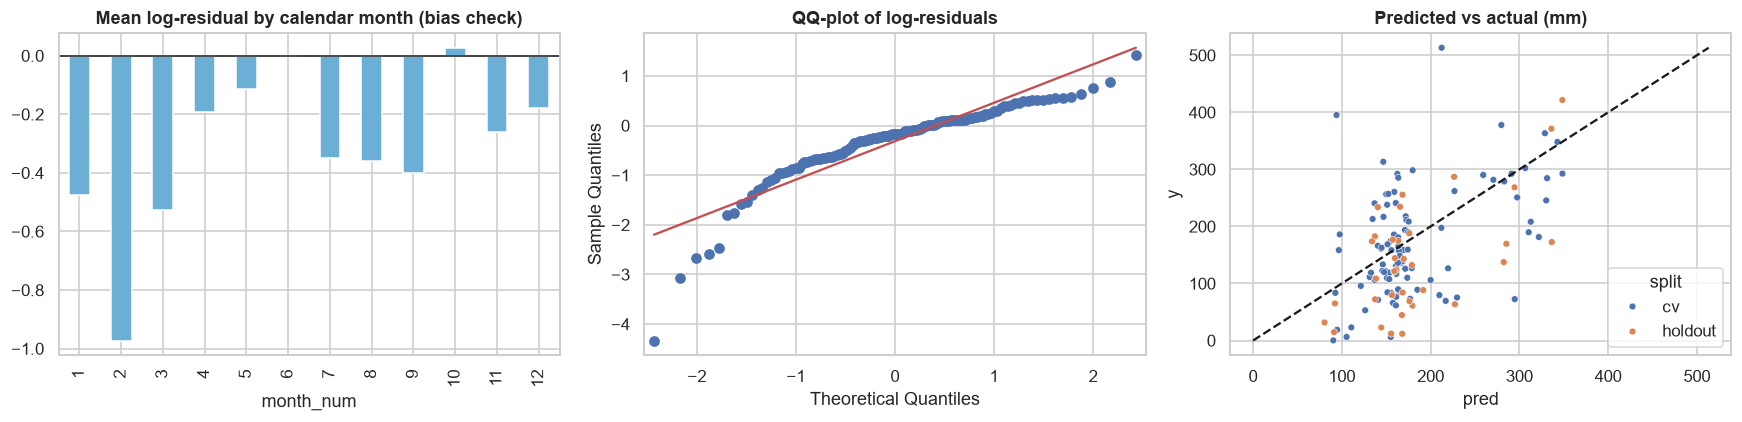

Mean error (pred - actual): all months +20.5 mm | wettest-10% months -88.2 mm (n=14)
Calibration note: the wettest months are strongly under-predicted (regression to the seasonal mean) - a structural limit of mean-type forecasts, and the reason extremes are modelled separately (Sections 4 and 8).


In [71]:
# Residual diagnostics for the ensemble: bias by calendar month and residual normality (log scale)
ens["month_num"] = ens.date.dt.month
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ens.groupby("month_num").r.mean().plot.bar(ax=axes[0], color="#6baed6"); axes[0].axhline(0, color="k", lw=1)
axes[0].set_title("Mean log-residual by calendar month (bias check)")
sm.qqplot(ens.r.values, line="s", ax=axes[1]); axes[1].set_title("QQ-plot of log-residuals")
sns.scatterplot(data=ens, x="pred", y="y", hue="split", ax=axes[2], s=20); lim = [0, max(ens.y.max(), ens.pred.max())]
axes[2].plot(lim, lim, "k--"); axes[2].set_title("Predicted vs actual (mm)")
plt.tight_layout(); plt.show()
top = ens[ens.y >= ens.y.quantile(0.90)]
print(f"Mean error (pred - actual): all months {(ens.pred - ens.y).mean():+.1f} mm | wettest-10% months {(top.pred - top.y).mean():+.1f} mm (n={len(top)})")
print("Calibration note: the wettest months are strongly under-predicted (regression to the seasonal mean) - a structural limit of mean-type forecasts, and the reason extremes are modelled separately (Sections 4 and 8).")

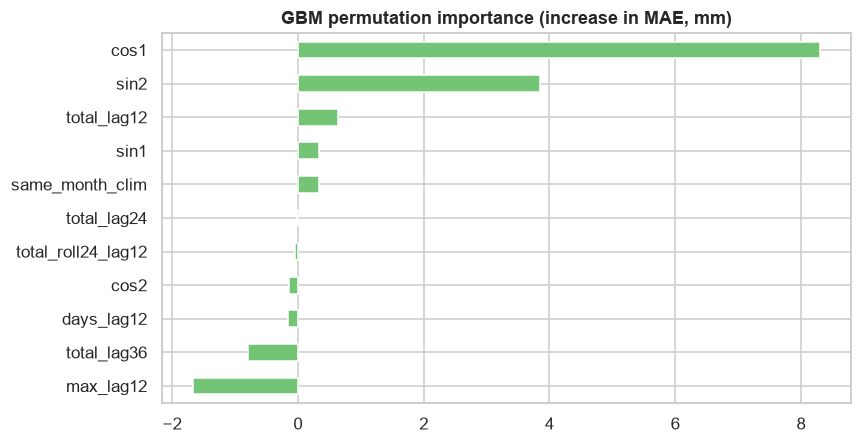

In [72]:
# What is the GBM using? Permutation importance computed on CV-style data (refit on pre-holdout, scored on holdout)
from sklearn.inspection import permutation_importance
tr_idx = y_all[: HOLDOUT_ORIGINS[0] - pd.DateOffset(months=1)].dropna().index
te_idx = y_all[HOLDOUT_ORIGINS[0]: HOLDOUT_ORIGINS[-1] + pd.DateOffset(months=11)].index
gbm = HistGradientBoostingRegressor(**GBM_PARAMS).fit(FEATS.loc[tr_idx], y_all.loc[tr_idx].clip(lower=0.1))
pi = permutation_importance(gbm, FEATS.loc[te_idx], y_all.loc[te_idx], n_repeats=30, random_state=SEED,
                            scoring="neg_mean_absolute_error")
imp = pd.Series(pi.importances_mean, index=FEATS.columns).sort_values()
imp.plot.barh(figsize=(8, 4.2), color="#74c476"); plt.title("GBM permutation importance (increase in MAE, mm)"); plt.tight_layout(); plt.show()

## 8. Extreme-month risk
Mean forecasts are weakest exactly where the stakes are highest. I define an **extreme month** as one whose *highest daily total exceeds the 90th percentile of the pre-holdout period* (threshold learned from training data only), then:
1. Estimate **risk by calendar month** with a Beta posterior (honest small-sample uncertainty, not raw proportions).
2. Fit a **logistic model** on leak-free features and judge it by **Brier skill score** and **AUC** on the last 10 years (Jul-2010 → Jun-2020; the 36-month forecasting holdout contains *zero* extreme months, so it cannot evaluate a rare-event classifier) vs. a base-rate model, with the threshold and all fitted values learned only from data before Jul-2010.

Extreme-month threshold (90th pct of pre-2010-07 highest-daily-total): 102.6 mm | base rate (train) = 10.2%


,events,years,post_mean,ci_lo,ci_hi
month_num,,,,,
1,9,29,0.32,0.19,0.47
2,2,29,0.10,0.03,0.20
3,2,29,0.10,0.03,0.20
4,0,29,0.03,0.00,0.10
5,1,29,0.06,0.01,0.15
6,1,29,0.06,0.01,0.15
7,0,28,0.03,0.00,0.10
8,4,28,0.17,0.07,0.29
9,1,28,0.07,0.01,0.15


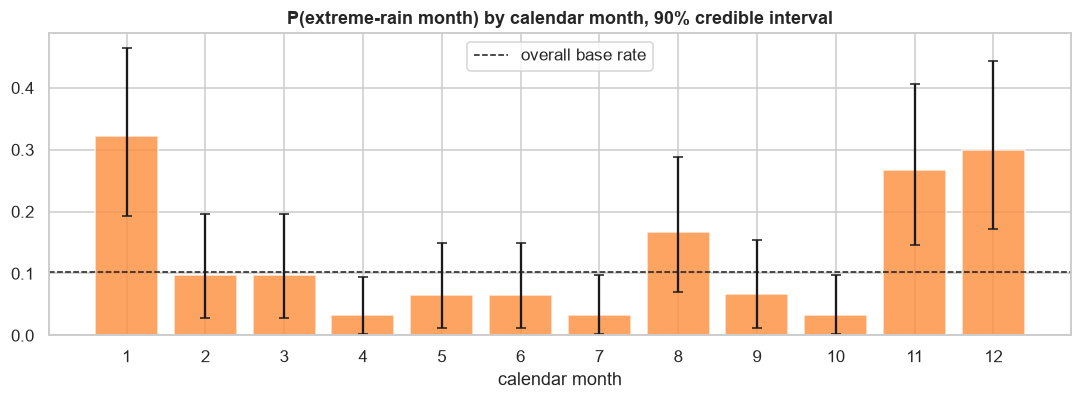

In [73]:
split_date = pd.Timestamp("2010-07-01")   # evaluation window = last 10 years (36 holdout months contain no events)
train_mask = df.index < split_date
THRESH = df.loc[train_mask, "max_daily_mm"].quantile(0.90)
df["extreme"] = (df.max_daily_mm > THRESH).astype(int)
print(f"Extreme-month threshold (90th pct of pre-2010-07 highest-daily-total): {THRESH:.1f} mm | base rate (train) = {df.loc[train_mask,'extreme'].mean():.1%}")

tr = df[train_mask]
g = tr.groupby("month_num").extreme.agg(["sum", "count"])
post = pd.DataFrame({"events": g["sum"], "years": g["count"]})
post["post_mean"] = (1 + post.events) / (2 + post.years)                    # Beta(1,1) prior
post["ci_lo"] = stats.beta.ppf(0.05, 1 + post.events, 1 + post.years - post.events)
post["ci_hi"] = stats.beta.ppf(0.95, 1 + post.events, 1 + post.years - post.events)
display(post.round(2))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(post.index, post.post_mean, color="#fd8d3c", alpha=0.8, yerr=[post.post_mean - post.ci_lo, post.ci_hi - post.post_mean], capsize=3)
ax.axhline(tr.extreme.mean(), color="k", ls="--", lw=1, label="overall base rate"); ax.set_xticks(range(1, 13))
ax.set_title("P(extreme-rain month) by calendar month, 90% credible interval"); ax.set_xlabel("calendar month"); ax.legend()
plt.tight_layout(); plt.show()

In [74]:
XF = FEATS.loc[df.index].copy(); XF = XF.fillna(XF.loc[train_mask].median())   # train-only imputation values
cols = ["sin1", "cos1", "sin2", "cos2", "total_roll24_lag12", "max_lag12", "same_month_clim"]
mu, sd = XF.loc[train_mask, cols].mean(), XF.loc[train_mask, cols].std()
Z = (XF[cols] - mu) / sd
tr_m, te_m = train_mask, df.index >= split_date
clf = LogisticRegression(C=0.5, max_iter=1000).fit(Z[tr_m], df.extreme[tr_m])
p_te = clf.predict_proba(Z[te_m])[:, 1]; y_te = df.extreme[te_m].values
base = np.full_like(p_te, df.extreme[tr_m].mean())
bs_model, bs_base = brier_score_loss(y_te, p_te), brier_score_loss(y_te, base)
print(f"Eval window 2010-07 to 2020-06 (n={len(y_te)}, events={y_te.sum()}) | Brier model {bs_model:.3f} vs base-rate {bs_base:.3f} | "
      f"Brier skill = {1 - bs_model / bs_base:+.1%} | AUC = {roc_auc_score(y_te, p_te):.2f}")
print("Interpretation: compare Brier skill to 0 (no better than the base rate) and AUC to 0.5 (no discrimination). Few events => wide uncertainty on both.")
THRESH_ALL = df.max_daily_mm.quantile(0.90)       # production values: refit on ALL data
g2 = df.assign(ext=(df.max_daily_mm > THRESH_ALL).astype(int)).groupby("month_num").ext.agg(["sum", "count"])
post_all = (1 + g2["sum"]) / (2 + g2["count"])

Eval window 2010-07 to 2020-06 (n=120, events=4) | Brier model 0.039 vs base-rate 0.037 | Brier skill = -5.9% | AUC = 0.73
Interpretation: compare Brier skill to 0 (no better than the base rate) and AUC to 0.5 (no discrimination). Few events => wide uncertainty on both.


## 9. Production forecast: next 12 months
All models are refit on **all 462 months** and the next 12 months (Jul-2020 → Jun-2021) are forecast with the calibrated 90% interval. Same feature code, same leakage guarantee.

,ETS,DHR-ARIMA,GBM,forecast_mm,lo90,hi90,p_extreme_month,model_spread_mm
2020-07-01,128.0,169.0,195.4,164.1,38.6,289.8,0.1,67.4
2020-08-01,130.8,183.7,131.9,148.8,34.9,262.8,0.1,52.9
2020-09-01,122.3,136.6,119.3,126.1,29.5,222.8,0.1,17.4
2020-10-01,138.5,170.8,171.4,160.2,37.7,283.0,0.0,32.9
2020-11-01,241.9,288.7,237.9,256.1,60.7,451.9,0.2,50.7
2020-12-01,292.9,375.8,311.3,326.7,77.6,576.1,0.2,82.9
2021-01-01,180.5,176.8,163.5,173.6,40.9,306.5,0.3,17.0
2021-02-01,62.1,97.5,203.6,121.1,28.3,214.0,0.1,141.5
2021-03-01,126.2,114.5,104.3,115.0,26.8,203.3,0.1,22.0
2021-04-01,141.6,192.3,175.1,169.7,39.9,299.6,0.1,50.6


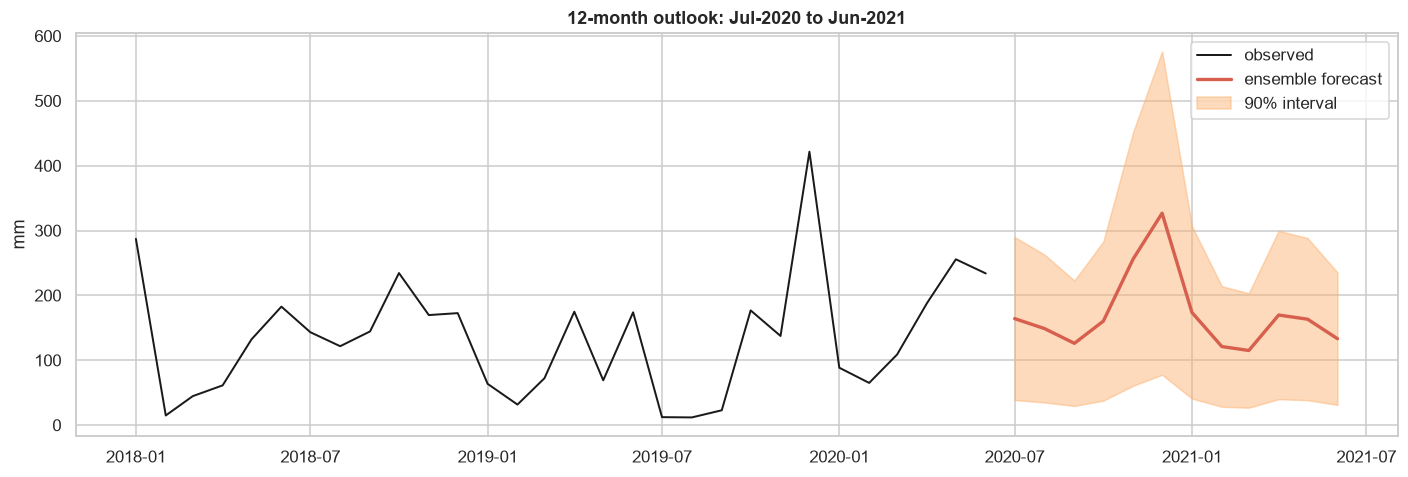

Saved: ['backtest_metrics.csv', 'backtest_predictions.csv', 'forecast_next_12_months.csv', 'gev_return_levels.csv', 'model_card.json']


In [75]:
FINAL_ORIGIN = pd.Timestamp("2020-07-01")
fidx = pd.date_range(FINAL_ORIGIN, periods=12, freq="MS")
preds = {n: f(FINAL_ORIGIN, fidx) for n, f in {"ETS": fc_ets, "DHR-ARIMA": fc_dhr, "GBM": fc_gbm}.items()}
fc = pd.DataFrame(preds, index=fidx); fc["forecast_mm"] = fc.mean(axis=1)
fc["lo90"], fc["hi90"] = interval(fc.forecast_mm)
fc["p_extreme_month"] = [post_all[m] for m in fc.index.month]
fc["model_spread_mm"] = fc[["ETS", "DHR-ARIMA", "GBM"]].max(axis=1) - fc[["ETS", "DHR-ARIMA", "GBM"]].min(axis=1)
display(fc.round(1))

hist = df.total_mm["2018-01":]
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(hist.index, hist, color="k", lw=1.3, label="observed")
ax.plot(fc.index, fc.forecast_mm, color="#d6604d", lw=2.2, label="ensemble forecast")
ax.fill_between(fc.index, fc.lo90, fc.hi90, color="#fdae6b", alpha=0.45, label="90% interval")
ax.set_title("12-month outlook: Jul-2020 to Jun-2021"); ax.set_ylabel("mm"); ax.legend()
plt.tight_layout(); plt.show()

fc.round(2).to_csv(ARTIFACT_DIR / "forecast_next_12_months.csv")
bt.to_csv(ARTIFACT_DIR / "backtest_predictions.csv", index=False)
res.to_csv(ARTIFACT_DIR / "backtest_metrics.csv"); rl_tbl.round(1).to_csv(ARTIFACT_DIR / "gev_return_levels.csv")
json.dump({"selected_dhr": {"K": int(BEST.K), "p": int(BEST.p), "q": int(BEST.q)}, "gbm_params": GBM_PARAMS,
           "conformal_log_quantiles": [float(q_lo), float(q_hi)], "extreme_threshold_mm": float(THRESH_ALL),
           "mase_scale": float(MASE_SCALE), "seed": SEED}, open(ARTIFACT_DIR / "model_card.json", "w"), indent=2)
print("Saved:", sorted(p.name for p in ARTIFACT_DIR.iterdir()))

## 10. Summary About the Project

In [26]:
h, c = res.loc["holdout"], res.loc["cv"]
trend = trend_tbl.loc["total_mm"]; trend_x = trend_tbl.loc["max_daily_mm"]
best_cv = c.loc[order, "MAE"].idxmin()
top3 = ", ".join(pd.Timestamp(2000, m, 1).strftime("%b") for m in clim.mean_mm.nlargest(3).index)
p_clim, p_snaive = sig.loc["Ensemble vs Climatology", "wilcoxon_p"], sig.loc["Ensemble vs Seasonal-naive", "wilcoxon_p"]
verdict = ("**no model is statistically distinguishable from plain monthly climatology**" if p_clim > 0.05
           else "**the ensemble significantly beats climatology**")
tr_d, tr_i = trend_tbl.loc["rain_days"], trend_tbl.loc["intensity"]
display(Markdown(f'''
**Data.** {len(df)} monthly observations ({df.index.min():%b %Y}-{df.index.max():%b %Y}); all data-contract checks passed.

**Seasonality is real but moderate.** STL seasonal strength is **{Fs:.2f}** (0 = none, 1 = deterministic). The wettest months on average are **{top3}** and the wettest/driest month ratio is **{clim.mean_mm.max()/clim.mean_mm.min():.1f}x**, yet most month-to-month variation is irregular. Rain-day frequency explains **{cov_d:.0%}** and intensity **{cov_i:.0%}** of the variance in log monthly rainfall.

**Trends.** Annual total rainfall shows no significant trend (MK p = **{trend.MK_p:.2f}**, Theil-Sen {trend.sen_slope_per_year:+.1f} mm/yr, 95% CI {trend.slope_CI_lo:+.1f} to {trend.slope_CI_hi:+.1f}). Rainy days per year trend **{tr_d.sen_slope_per_year:+.2f}/yr** (p = {tr_d.MK_p:.3f}) while intensity trends **{tr_i.sen_slope_per_year:+.2f} mm/rain-day/yr** (p = {tr_i.MK_p:.3f}; Pettitt shift ~{int(tr_i.pettitt_change_year)}, p = {tr_i.pettitt_p:.3f}). With four metrics tested, only the intensity result is near the Bonferroni threshold of {0.05/4:.4f}.

**Extremes.** GEV tail index xi = **{xi:.2f}** (bounded/light tail, KS p = {ks.pvalue:.2f}). 10-year daily return level ~ **{rl_tbl.loc[10,'level_mm']:.0f} mm** (95% CI {rl_tbl.loc[10,'CI95_lo']:.0f}-{rl_tbl.loc[10,'CI95_hi']:.0f}); 50-year ~ **{rl_tbl.loc[50,'level_mm']:.0f} mm** (CI {rl_tbl.loc[50,'CI95_lo']:.0f}-{rl_tbl.loc[50,'CI95_hi']:.0f}). The record maximum is {df.max_daily_mm.max():.0f} mm ({df.max_daily_mm.idxmax():%b %Y}).

**Forecasting (12-month horizon, rolling origin).** On the untouched holdout, MAE: ensemble **{h.loc['Ensemble','MAE']:.1f} mm**, climatology **{h.loc['Climatology','MAE']:.1f} mm**, seasonal-naive **{h.loc['Seasonal-naive','MAE']:.1f} mm**. The paired test shows the ensemble beats seasonal-naive (p = {p_snaive:.3f}) but {verdict} (p = {p_clim:.2f}). 12-months-ahead monthly rainfall is largely unpredictable beyond its seasonal climatology with this information set. All models over-forecast the holdout (ensemble bias **{h.loc['Ensemble','Bias']:+.0f} mm**, climatology **{h.loc['Climatology','Bias']:+.0f} mm**): 2017-2020 was drier than the 1982-2017 history, a reminder that climatology is only as good as its stationarity assumption.

**Uncertainty.** 90% conformal intervals achieved **{cov:.0%}** holdout coverage but are wide (mean width {np.mean(ho.hi - ho.lo):.0f} mm vs. mean actual {ho.y.mean():.0f} mm) - that width *is* the honest message.

**Extreme-month risk.** Brier skill vs. base rate **{1 - bs_model / bs_base:+.1%}**, AUC **{roc_auc_score(y_te, p_te):.2f}** on {len(y_te)} months with {int(y_te.sum())} events: little beyond calendar seasonality can be claimed.
'''))


**Data.** 462 monthly observations (Jan 1982-Jun 2020); all data-contract checks passed.

**Seasonality is real but moderate.** STL seasonal strength is **0.35** (0 = none, 1 = deterministic). The wettest months on average are **Dec, Nov, Jan** and the wettest/driest month ratio is **3.0x**, yet most month-to-month variation is irregular. Rain-day frequency explains **43%** and intensity **57%** of the variance in log monthly rainfall.

**Trends.** Annual total rainfall shows no significant trend (MK p = **0.48**, Theil-Sen -5.4 mm/yr, 95% CI -20.2 to +11.0). Rainy days per year trend **+0.60/yr** (p = 0.045) while intensity trends **-0.08 mm/rain-day/yr** (p = 0.015; Pettitt shift ~2007, p = 0.043). With four metrics tested, only the intensity result is near the Bonferroni threshold of 0.0125.

**Extremes.** GEV tail index xi = **-0.14** (bounded/light tail, KS p = 0.48). 10-year daily return level ~ **187 mm** (95% CI 160-207); 50-year ~ **232 mm** (CI 186-282). The record maximum is 216 mm (Jan 2011).

**Forecasting (12-month horizon, rolling origin).** On the untouched holdout, MAE: ensemble **73.4 mm**, climatology **74.7 mm**, seasonal-naive **82.2 mm**. The paired test shows the ensemble beats seasonal-naive (p = 0.011) but **no model is statistically distinguishable from plain monthly climatology** (p = 0.30). 12-months-ahead monthly rainfall is largely unpredictable beyond its seasonal climatology with this information set. All models over-forecast the holdout (ensemble bias **+43 mm**, climatology **+38 mm**): 2017-2020 was drier than the 1982-2017 history, a reminder that climatology is only as good as its stationarity assumption.

**Uncertainty.** 90% conformal intervals achieved **89%** holdout coverage but are wide (mean width 281 mm vs. mean actual 141 mm) - that width *is* the honest message.

**Extreme-month risk.** Brier skill vs. base rate **-5.9%**, AUC **0.73** on 120 months with 4 events: little beyond calendar seasonality can be claimed.
